# ПРАКТИЧЕСКОЕ ЗАДАНИЕ 5. КЛАСТЕРИЗАЦИЯ ДАННЫХ


K-средних
Количество кластеров: 3
Коэффициент силуэта: 0.460
ARI: 0.620

Иерархическая кластеризация
Количество кластеров: 3
Коэффициент силуэта: 0.447
ARI: 0.615

DBSCAN
Количество кластеров: 3
Количество шумовых точек: 89
Коэффициент силуэта: 0.710
ARI: 0.279


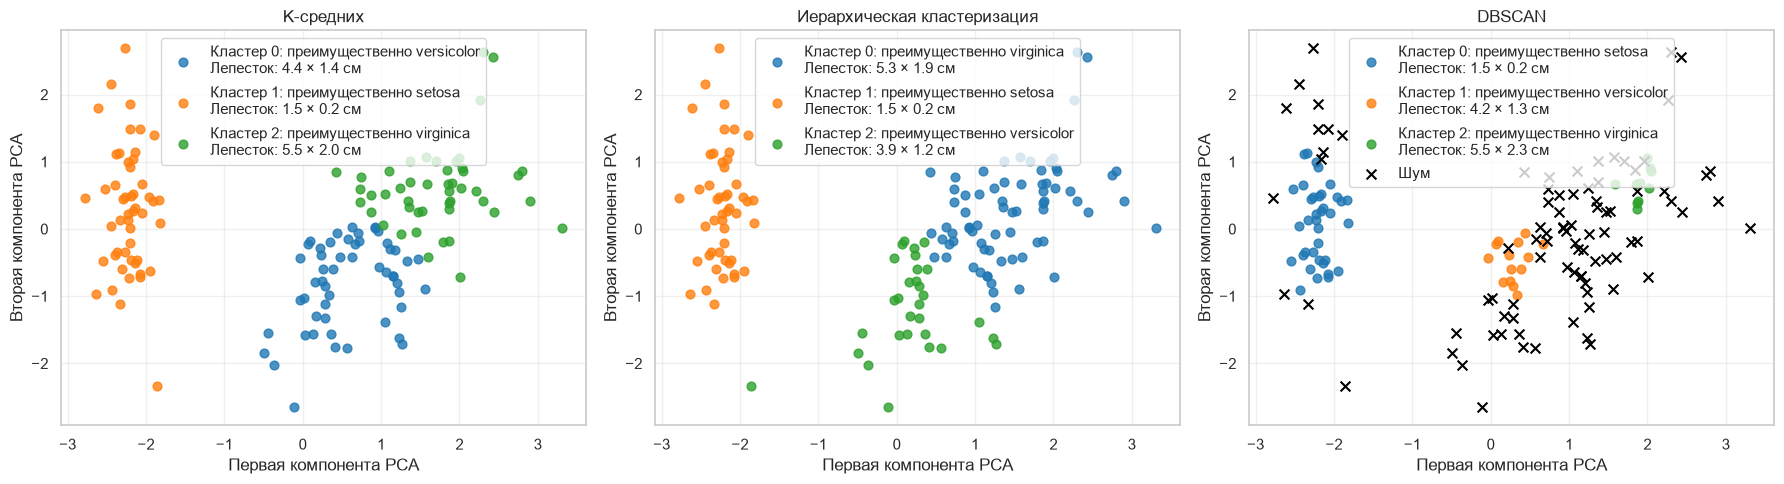

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score



iris = load_iris()
X = iris.data
y_true = iris.target  

X_scaled = StandardScaler().fit_transform(X)


X_pca = PCA(n_components=2).fit_transform(X_scaled)



models = {
    "K-средних": KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ),
    "Иерархическая кластеризация": AgglomerativeClustering(
        n_clusters=3,
        linkage="ward"
    ),
    "DBSCAN": DBSCAN(
        eps=0.5,
        min_samples=10
    )
}



fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    labels = model.fit_predict(X_scaled)


    cluster_labels = set(labels) - {-1}
    n_clusters = len(cluster_labels)
    noise_mask = labels == -1
    n_noise = noise_mask.sum()

    print(f"\n{name}")
    print(f"Количество кластеров: {n_clusters}")

    if name == "DBSCAN":
        print(f"Количество шумовых точек: {n_noise}")


    non_noise_mask = ~noise_mask
    labels_for_silhouette = labels[non_noise_mask]
    n_samples_for_silhouette = non_noise_mask.sum()

    if 2 <= n_clusters < n_samples_for_silhouette:
        silhouette = silhouette_score(
            X_scaled[non_noise_mask],
            labels_for_silhouette
        )
        print(f"Коэффициент силуэта: {silhouette:.3f}")
    else:
        print("Коэффициент силуэта: невозможно вычислить")

    ari = adjusted_rand_score(y_true, labels)
    print(f"ARI: {ari:.3f}")


    colors = plt.cm.tab10.colors


    for i, cluster in enumerate(sorted(cluster_labels)):
        mask = labels == cluster


        species_counts = np.bincount(y_true[mask], minlength=3)
        dominant_species = iris.target_names[species_counts.argmax()]


        mean_petal_length = X[mask, 2].mean()
        mean_petal_width = X[mask, 3].mean()

        label = (
            f"Кластер {cluster}: преимущественно {dominant_species}\n"
            f"Лепесток: {mean_petal_length:.1f} × "
            f"{mean_petal_width:.1f} см"
        )

        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            color=colors[i % len(colors)],
            label=label,
            s=40,
            alpha=0.8
        )

    if n_noise > 0:
        ax.scatter(
            X_pca[noise_mask, 0],
            X_pca[noise_mask, 1],
            color="black",
            marker="x",
            label="Шум",
            s=50
        )

    ax.set_title(name)
    ax.set_xlabel("Первая компонента PCA")
    ax.set_ylabel("Вторая компонента PCA")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Кластеризация на основе безразмерных комплексов
Количество кластеров: 3
Коэффициент силуэта: 0.668
ARI: 0.868


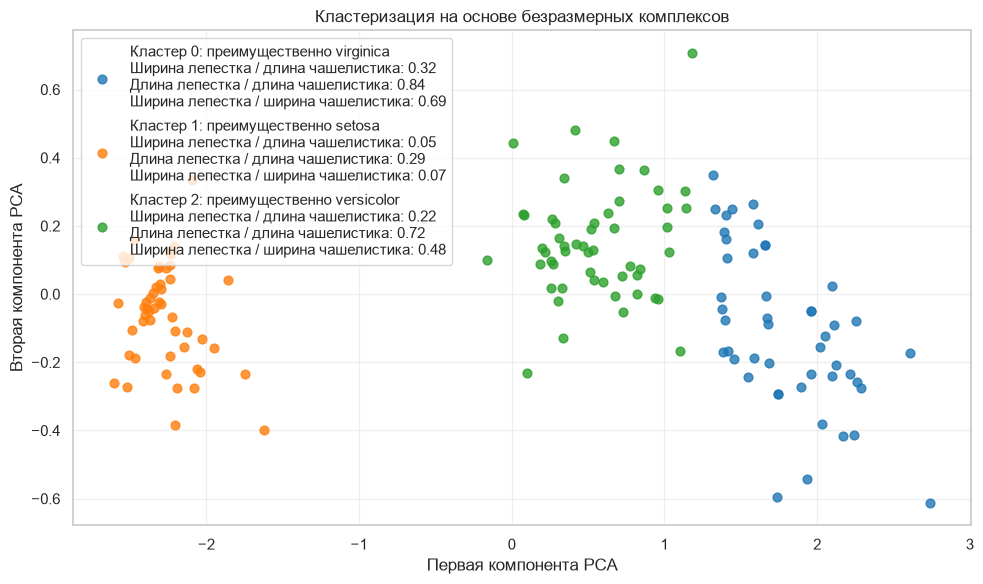

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score


# 1. Загрузка данных
iris = load_iris()
X = iris.data
y_true = iris.target

sepal_length = X[:, 0]
sepal_width = X[:, 1]
petal_length = X[:, 2]
petal_width = X[:, 3]




complexes = np.column_stack([
    petal_width / sepal_length,
    petal_length / sepal_length,
    petal_width / sepal_width,
    
])


complexes_scaled = StandardScaler().fit_transform(complexes)


model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(complexes_scaled)



print("Кластеризация на основе безразмерных комплексов")
print(f"Количество кластеров: {len(np.unique(labels))}")
print(
    f"Коэффициент силуэта: "
    f"{silhouette_score(complexes_scaled, labels):.3f}"
)
print(f"ARI: {adjusted_rand_score(y_true, labels):.3f}")



complexes_pca = PCA(n_components=2).fit_transform(complexes_scaled)

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.tab10.colors

for cluster in sorted(np.unique(labels)):
    mask = labels == cluster


    species_counts = np.bincount(y_true[mask], minlength=3)
    dominant_species = iris.target_names[species_counts.argmax()]


    mean_width_to_sepal_length = complexes[mask, 0].mean()
    mean_length_to_sepal_length = complexes[mask, 1].mean()
    mean_width_to_sepal_width = complexes[mask, 2].mean()

    label = (
        f"Кластер {cluster}: преимущественно {dominant_species}\n"
        f"Ширина лепестка / длина чашелистика: "
        f"{mean_width_to_sepal_length:.2f}\n"
        f"Длина лепестка / длина чашелистика: "
        f"{mean_length_to_sepal_length:.2f}\n"
        f"Ширина лепестка / ширина чашелистика: "
        f"{mean_width_to_sepal_width:.2f}"
    )

    ax.scatter(
        complexes_pca[mask, 0],
        complexes_pca[mask, 1],
        color=colors[cluster % len(colors)],
        label=label,
        s=40,
        alpha=0.8
    )

ax.set_title("Кластеризация на основе безразмерных комплексов")
ax.set_xlabel("Первая компонента PCA")
ax.set_ylabel("Вторая компонента PCA")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()